# Robot log viewer

In [ ]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

LOG_PATH = "test-turnrate_11.log"     
SHADE_STATES = True            


plt.rcParams.update({
    "figure.figsize": (11, 4),
    "figure.constrained_layout.use": True,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "lines.linewidth": 1.3,
})

COLUMNS = [
    "time", "state", "desired_vel",
    "volt_left", "volt_right",
    "enc_left", "enc_right",
    "vel_left", "vel_right",
    "battery",
    "gyro_x", "gyro_y", "gyro_z",
    "cur_left", "cur_right",
    "pose_x", "pose_y", "heading", "distance",
    "forward_vel", "turn_rate",
    "desired_turn_rate"
]

log_path = Path(LOG_PATH)
if not log_path.is_file():
    raise FileNotFoundError(f"Log file not found: {log_path.resolve()}")

header = [l.strip("% \n") for l in log_path.read_text().splitlines() if l.startswith("%")]

data = pd.read_csv(log_path, comment="%", sep=r"\s+", header=None)
if data.shape[1] != len(COLUMNS):
    print(f"Warning: expected {len(COLUMNS)} columns, found {data.shape[1]}")
data = data.iloc[:, :len(COLUMNS)]
data.columns = COLUMNS[:data.shape[1]]

t = data["time"]
title = header[0] if header else log_path.name
print("\n".join(header[:3]))
print(f"{len(data)} samples, {t.iloc[0]:.3f} to {t.iloc[-1]:.3f} s")
data.head()

FileNotFoundError: Log file not found: /home/luma/DTU/MA2/Digital Control/DigitalControlProject/basebot_6_50/logs/test-turnrate_11.log

In [ ]:
def state_shading(ax):
    """Light background bands that show when the robot state changes."""
    if not SHADE_STATES:
        return
    s = data["state"]
    change = s.ne(s.shift()).cumsum()
    cmap = plt.get_cmap("tab10")
    for _, seg in data.groupby(change):
        ax.axvspan(seg["time"].iloc[0], seg["time"].iloc[-1],
                   color=cmap(int(seg["state"].iloc[0]) % 10), alpha=0.07, lw=0)


def finish(ax, ylabel, ptitle, legend=True):
    state_shading(ax)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(ylabel)
    ax.set_title(ptitle)
    if legend:
        ax.legend(loc="best")

def plot(cols_labels, ylabel, ptitle, **kw):
    fig, ax = plt.subplots()
    for col, label in cols_labels:
        ax.plot(t, data[col], label=label, **kw)
    finish(ax, ylabel, ptitle)
    return ax

## Overview
State and desired velocity

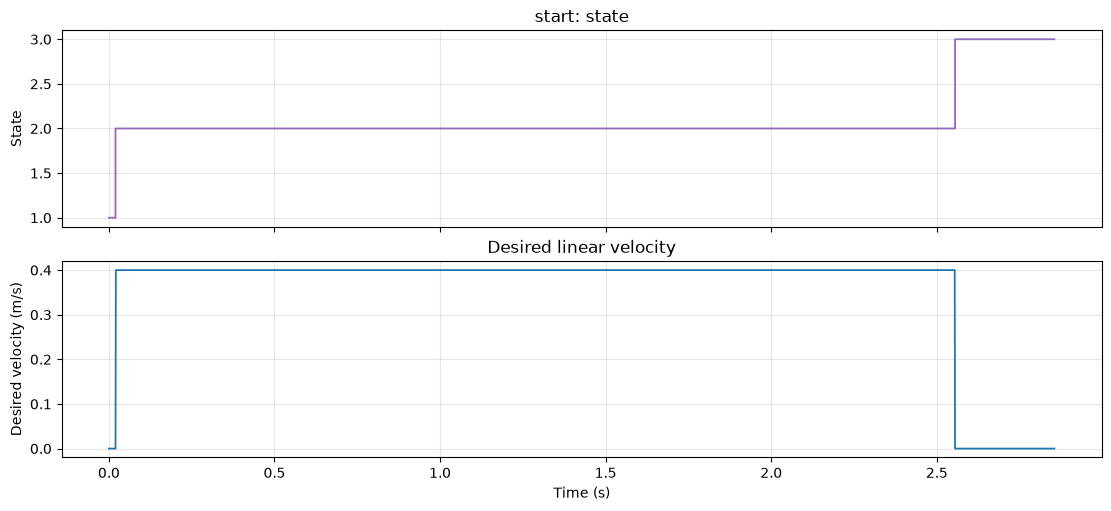

In [ ]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(11, 5))
axes[0].step(t, data["state"], where="post", color="tab:purple")
axes[0].set_ylabel("State"); axes[0].set_title(f"{title}: state")
axes[1].plot(t, data["desired_vel"], color="tab:blue")
axes[1].set_ylabel("Desired velocity (m/s)"); axes[1].set_xlabel("Time (s)")
axes[1].set_title("Desired linear velocity")
plt.show()

## Speed and distance

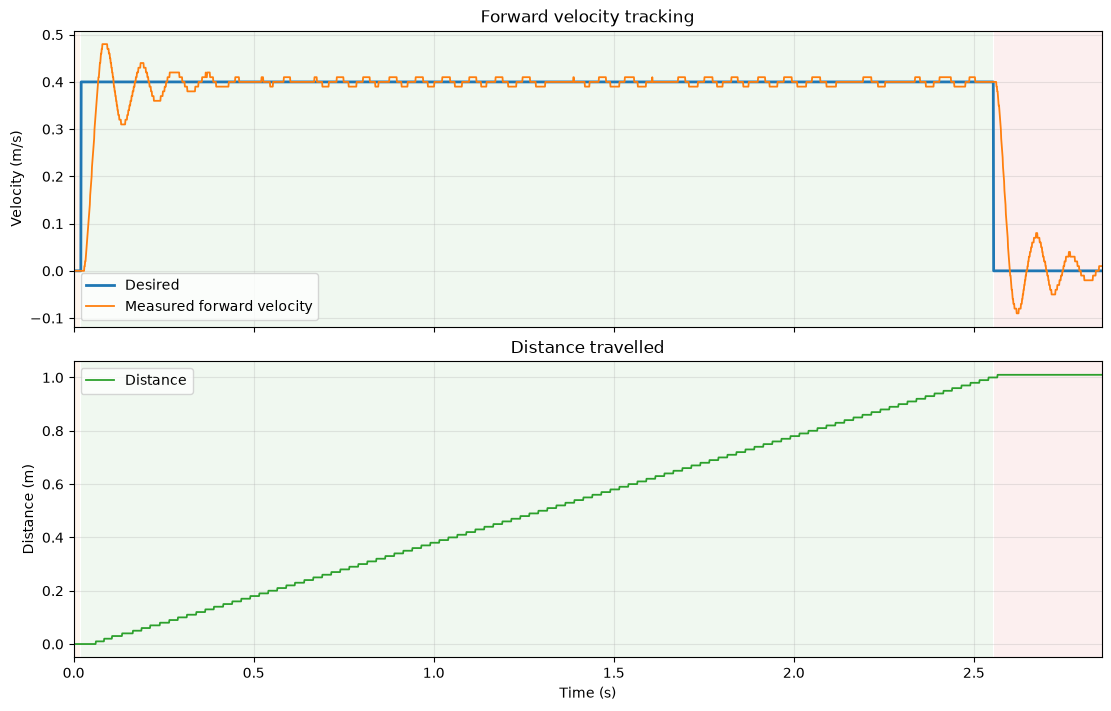

In [ ]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(11, 7))
axes[0].plot(t, data["desired_vel"], label="Desired", lw=2)
axes[0].plot(t, data["forward_vel"], label="Measured forward velocity")
finish(axes[0], "Velocity (m/s)", "Forward velocity tracking")
axes[0].set_xlabel("")
axes[1].plot(t, data["distance"], color="tab:green", label="Distance")
finish(axes[1], "Distance (m)", "Distance travelled")
plt.xlim(0.0, max(t))
plt.show()

## Motors

In [3]:
plot([("volt_left", "Left"), ("volt_right", "Right")], "Voltage (V)", "Motor voltage")
plt.xlim(0.0, max(t))
plt.show()

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(11, 7))
for ax, side in zip(axes, ["left", "right"]):
    ax.plot(t, data[f"vel_{side}"])
    finish(ax, "Angular velocity (rad/s)", f"Motor velocity, {side}")
axes[0].set_xlabel("")
plt.xlim(0.0, max(t))
plt.show()

plot([("cur_left", "Left"), ("cur_right", "Right")], "Current (A)", "Motor current")
plt.xlim(0.0,max(t))
plt.show()

NameError: name 'plot' is not defined

## Heading and turning

NameError: name 't' is not defined

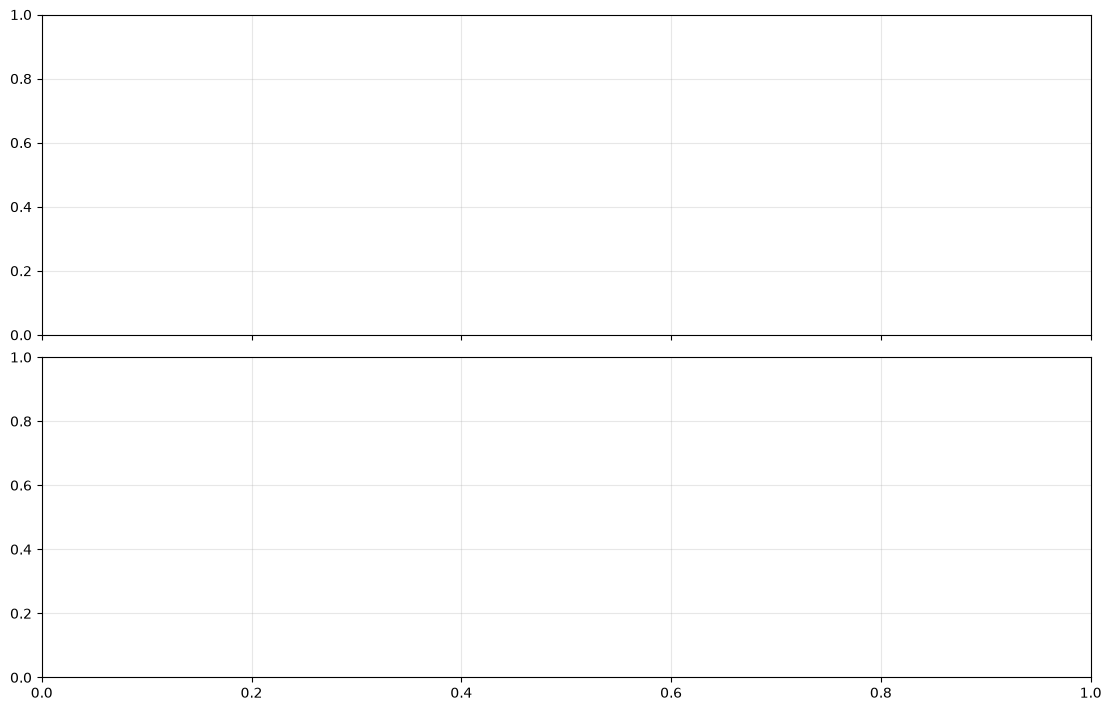

In [2]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(11, 7))

axes[0].plot(t, data["heading"], label="Heading")
finish(axes[0], "Heading (rad)", "Heading")
axes[0].set_xlabel("")

axes[1].plot(t, data["desired_turn_rate"], label="Desired", lw=2)
axes[1].plot(t, data["turn_rate"])
finish(axes[1], "Turn rate (rad/s)", "Turn rate tracking")
plt.xlim(0.0, max(t))
plt.show()

plot([("gyro_x", "x"), ("gyro_y", "y"), ("gyro_z", "z")], "Rate (deg/s)", "Gyro", alpha=0.85)
plt.xlim(0.0, max(t))
plt.show()

## Position

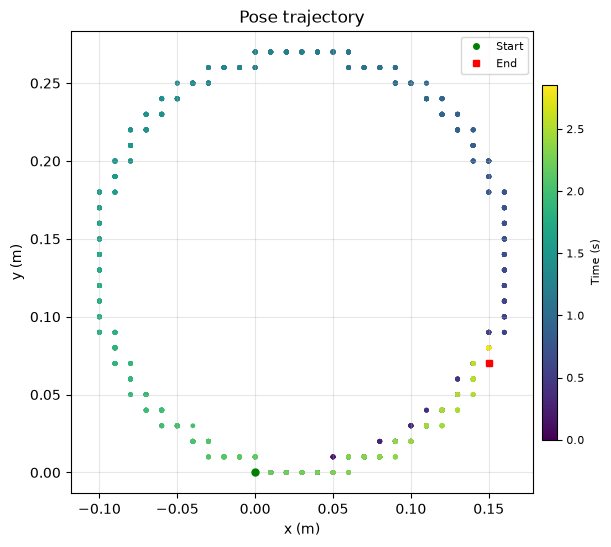

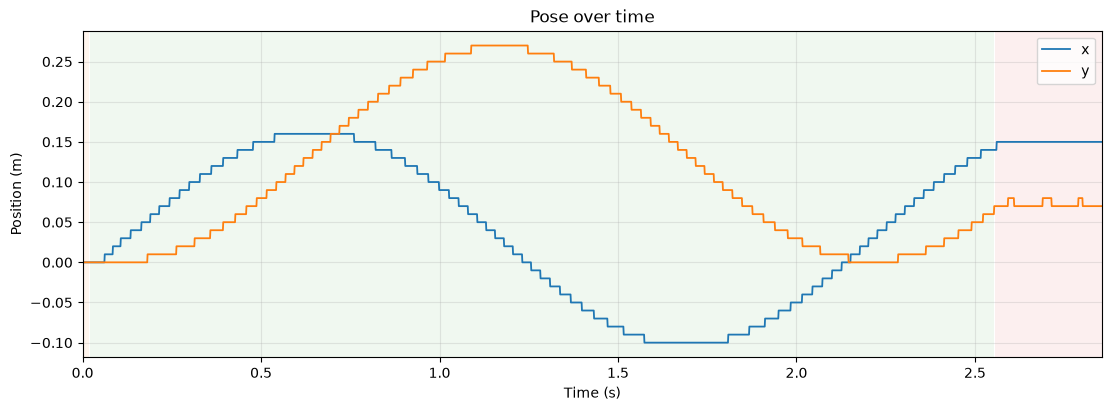

In [ ]:
from matplotlib.ticker import MultipleLocator

GRID_STEP = None

x, y = data["pose_x"], data["pose_y"]

fig, ax = plt.subplots(figsize=(6, 6))
sc = ax.scatter(x, y, c=t, s=6, cmap="viridis")
ax.plot(x.iloc[0],  y.iloc[0],  "go", markersize=5, label="Start")
ax.plot(x.iloc[-1], y.iloc[-1], "rs", markersize=5, label="End")

half = max(x.max() - x.min(), y.max() - y.min(), 0.2) / 2 * 1.1
cx, cy = (x.max() + x.min()) / 2, (y.max() + y.min()) / 2
ax.set_xlim(cx - half, cx + half)
ax.set_ylim(cy - half, cy + half)
ax.set_aspect("equal", adjustable="box")       

if GRID_STEP:
    ax.xaxis.set_major_locator(MultipleLocator(GRID_STEP))
    ax.yaxis.set_major_locator(MultipleLocator(GRID_STEP))

ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_title("Pose trajectory")

# Smaller colorbar and legend
cb = fig.colorbar(sc, ax=ax, shrink=0.6, aspect=25, pad=0.02)
cb.set_label("Time (s)", fontsize=8)
cb.ax.tick_params(labelsize=8)
ax.legend(fontsize=8, markerscale=0.8, loc="upper right", framealpha=0.8)
plt.show()

plot([("pose_x", "x"), ("pose_y", "y")], "Position (m)", "Pose over time")
plt.xlim(0.0, max(t))
plt.show()

## Encoders and battery

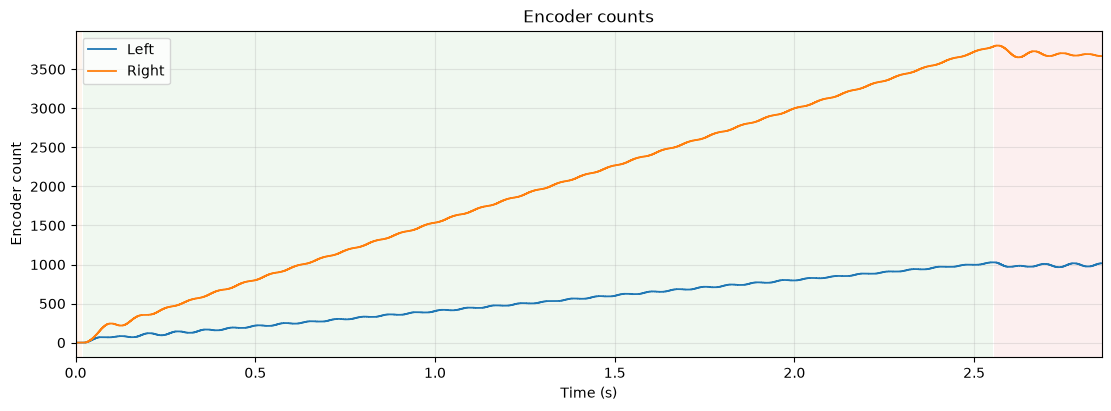

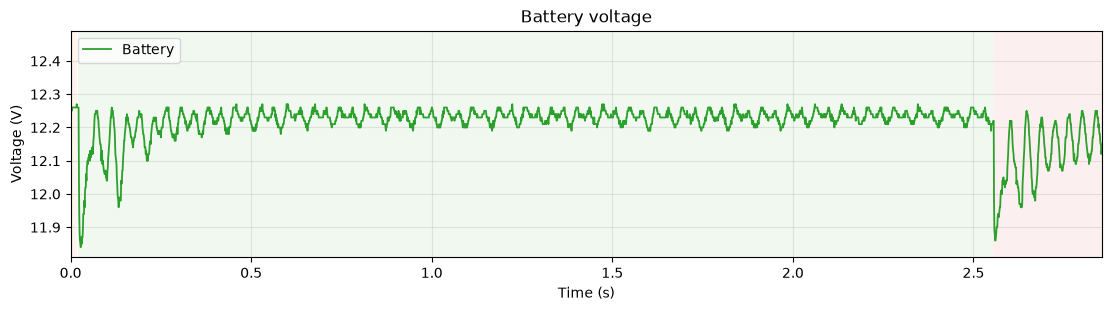

In [ ]:
fig, ax = plt.subplots()
ax.step(t, data["enc_left"], where="post", label="Left")
ax.step(t, data["enc_right"], where="post", label="Right")
finish(ax, "Encoder count", "Encoder counts")
plt.xlim(0.0, max(t))
plt.show()

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(t, data["battery"], color="tab:green", label="Battery")
finish(ax, "Voltage (V)", "Battery voltage")
plt.xlim(0.0, max(t))
plt.show()